# Text-to-Image Generation using Stable Diffusion 1.5

### Objective
This notebook demonstrates a complete, working Text-to-Image Generation application using **Stable Diffusion 1.5** in Google Colab. It features a modern, user-friendly **Gradio** web interface designed for a college Generative AI lab examination. Students will learn how to initialize pretrained diffusion models, apply memory optimizations, modify generative styles using engineered prompts, and design interactive user interfaces for inference.

In [18]:
# Check GPU availability and details
import torch

print("=== GPU Environment Check ===")
gpu_available = torch.cuda.is_available()
if gpu_available:
    device_name = torch.cuda.get_device_name(0)
    vram = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"GPU Detected: {device_name}")
    print(f"Total VRAM Available: {vram:.2f} GB")
else:
    print("WARNING: No GPU detected! Running on CPU fallback. Generation will be significantly slower.")

=== GPU Environment Check ===
GPU Detected: Tesla T4
Total VRAM Available: 14.56 GB


In [19]:
# Install required libraries
!pip install -q torch diffusers transformers accelerate safetensors gradio pillow

In [20]:
import os
import torch
from diffusers import StableDiffusionPipeline
from PIL import Image
import gradio as gr
import numpy as np

In [21]:
# Cell 5: Load pretrained Stable Diffusion 1.5 pipeline
import torch
from diffusers import StableDiffusionPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

print("Loading Stable Diffusion 1.5 weights... This may take a minute.")
try:
    # Load the model with FP16 weights if GPU is available to conserve memory
    if torch.cuda.is_available():
        pipe = StableDiffusionPipeline.from_pretrained(
            model_id,
            torch_dtype=torch.float16,
            safety_checker=None,
            requires_safety_checker=False
        )
    else:
        pipe = StableDiffusionPipeline.from_pretrained(
            model_id,
            torch_dtype=torch.float32,
            safety_checker=None,
            requires_safety_checker=False
        )
    print("Pipeline successfully loaded and cached!")
except Exception as e:
    print(f"Error loading the pipeline: {e}")

Loading Stable Diffusion 1.5 weights... This may take a minute.


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Pipeline successfully loaded and cached!


In [22]:
# Configure GPU, FP16 and memory optimizations
if torch.cuda.is_available():
    device = "cuda"
    # Move pipeline to GPU
    pipe = pipe.to(device)
    # Enable attention slicing to reduce memory usage during inference
    pipe.enable_attention_slicing()
    print("Pipeline optimized with GPU (CUDA), FP16 precision, and Attention Slicing.")
else:
    device = "cpu"
    print("Pipeline configured to run on CPU.")

Pipeline optimized with GPU (CUDA), FP16 precision, and Attention Slicing.


In [23]:
# Implement image generation function with prompts and styles
def generate_image(prompt, negative_prompt, style, steps, guidance_scale):
    # Apply style prompt wrappers
    style_templates = {
        "Realistic": "highly detailed, photorealistic, 8k resolution, raw photo, realistic lighting, masterpiece",
        "Anime": "anime aesthetic, studio ghibli style, vibrant colors, clean lineart, masterpiece, 4k",
        "Digital Art": "concept art, digital illustration, highly stylized, sharp focus, trend on artstation",
        "3D Render": "octane render, unreal engine 5, 3D modeling, hyper-realistic, global illumination",
        "Oil Painting": "classic oil on canvas painting, thick brush strokes, textured canvas, fine art style"
    }

    full_prompt = f"{prompt}, {style_templates.get(style, '')}"

    # Basic validation
    if not prompt.strip():
        raise ValueError("The prompt cannot be empty. Please provide a description!")

    try:
        # Clear GPU cache before generating
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        # Generate image using pipeline
        with torch.autocast(device):
            output = pipe(
                prompt=full_prompt,
                negative_prompt=negative_prompt,
                num_inference_steps=int(steps),
                guidance_scale=float(guidance_scale)
            )

        generated_img = output.images[0]
        return generated_img

    except RuntimeError as e:
        if "out of memory" in str(e).lower():
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            raise RuntimeError("GPU Out of Memory! Try lowering the inference steps or scale.")
        else:
            raise e

In [24]:
# Create and Launch the Gradio Web Interface
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("""# AI Text-to-Image Generator
    Create beautiful, high-quality images using a pretrained Stable Diffusion 1.5 model.
    """)

    with gr.Row():
        with gr.Column():
            prompt = gr.Textbox(
                label="Prompt",
                placeholder="An astronaut riding a horse on Mars...",
                value="A majestic castle on top of a mountain"
            )
            negative_prompt = gr.Textbox(
                label="Negative Prompt",
                placeholder="blurry, low quality, distorted, extra limbs...",
                value="low quality, blurry, distorted, bad anatomy"
            )
            style = gr.Dropdown(
                choices=["Realistic", "Anime", "Digital Art", "3D Render", "Oil Painting"],
                value="Digital Art",
                label="Image Style"
            )
            with gr.Row():
                steps = gr.Slider(minimum=10, maximum=30, value=20, step=1, label="Inference Steps")
                guidance_scale = gr.Slider(minimum=1.0, maximum=15.0, value=7.5, step=0.5, label="Guidance Scale")

            generate_btn = gr.Button("Generate Image", variant="primary")

        with gr.Column():
            output_image = gr.Image(label="Generated Image", type="pil")

    # Handle interactions
    generate_btn.click(
        fn=generate_image,
        inputs=[prompt, negative_prompt, style, steps, guidance_scale],
        outputs=output_image
    )

# Launch Gradio public share link
demo.launch(share=True, debug=False)

/tmp/ipykernel_681/4172126148.py:2: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://725801c2d8e68e9d7d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


=== Running Programmatic Dry-Run of Example 1 ===


  0%|          | 0/15 [00:00<?, ?it/s]

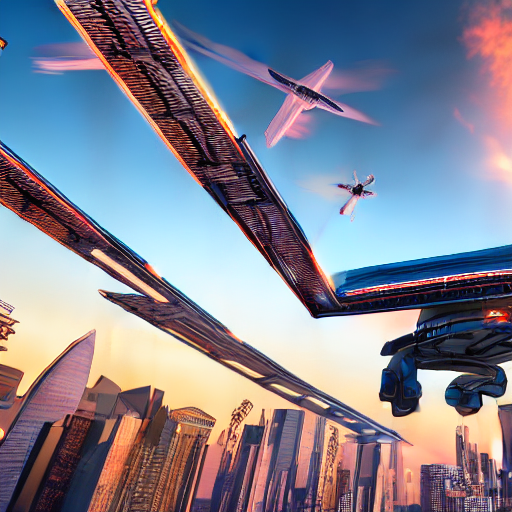

Example 1 generated successfully.


In [25]:
# Cell 10: Test with three example prompts (Scripted execution testing)
examples = [
    {"prompt": "A futuristic city with flying cars at sunset", "style": "Realistic"},
    {"prompt": "A magical forest with glowing mushrooms and fairies", "style": "Anime"},
    {"prompt": "A vintage steam locomotive crossing a bridge over a river", "style": "Oil Painting"}
]

print("=== Running Programmatic Dry-Run of Example 1 ===")
try:
    # Generate and display a single prompt automatically to verify API output
    test_img = generate_image(
        prompt=examples[0]["prompt"],
        negative_prompt="blurry, low quality",
        style=examples[0]["style"],
        steps=15,
        guidance_scale=7.5
    )
    display(test_img)
    print("Example 1 generated successfully.")
except Exception as e:
    print(f"Dry-run test skipped or encountered an issue: {e}")

## Exposing the Model as a FastAPI Backend (for Streamlit)

In [26]:
# Install backend and tunneling libraries
!pip install -q fastapi uvicorn pyngrok nest-asyncio

In [27]:
# Create and launch the FastAPI server
import nest_asyncio
from fastapi import FastAPI, HTTPException
from fastapi.responses import Response
from pydantic import BaseModel
import uvicorn
import threading
import io

# Allow nested asyncio loops in notebook runtimes
nest_asyncio.apply()

app = FastAPI(title="Stable Diffusion Backend API")

class GenerationRequest(BaseModel):
    prompt: str
    negative_prompt: str = ""
    style: str = "Realistic"
    steps: int = 20
    guidance_scale: float = 7.5

@app.post("/generate")
async def generate_endpoint(req: GenerationRequest):
    try:
        # Reuse the verified generate_image function from Cell 7
        pil_img = generate_image(
            prompt=req.prompt,
            negative_prompt=req.negative_prompt,
            style=req.style,
            steps=req.steps,
            guidance_scale=req.guidance_scale
        )

        # Save image to PNG bytes
        img_byte_arr = io.BytesIO()
        pil_img.save(img_byte_arr, format='PNG')
        img_byte_arr = img_byte_arr.getvalue()

        return Response(content=img_byte_arr, media_type="image/png")
    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))

# Run the API server in a separate background thread
def run_server():
    uvicorn.run(app, host="0.0.0.0", port=8000, log_level="warning")

threading.Thread(target=run_server, daemon=True).start()
print("FastAPI server successfully started in the background on port 8000!")

FastAPI server successfully started in the background on port 8000!


In [28]:
# Expose the FastAPI local server using ngrok tunnel
from pyngrok import ngrok
from google.colab import userdata

# Retrieve ngrok auth token from Colab Secrets (Add NGROK_AUTH_TOKEN in the left panel Secrets 🔑)
try:
    auth_token = userdata.get('NGROK_AUTH_TOKEN')
    ngrok.set_auth_token(auth_token)

    # Open tunnel
    public_url = ngrok.connect(8000)
    print("===============================================================")
    print(f"API Backend Exposed! Copy this Ngrok HTTPS URL for Streamlit:")
    print(f"{public_url.public_url}")
    print("===============================================================")
except Exception as e:
    print("Please add your 'NGROK_AUTH_TOKEN' to Google Colab Secrets (left sidebar 🔑 tab) to expose the API publicly.")
    print(f"Details: {e}")

ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8000): address already in use


API Backend Exposed! Copy this Ngrok HTTPS URL for Streamlit:
https://mural-snap-antiviral.ngrok-free.dev


## Streamlit Frontend Code
Create a local file named `app.py` on your computer, paste the following code, and execute `streamlit run app.py` in your terminal.

```python
import streamlit as st
import requests
from PIL import Image
import io

# Configure Streamlit page layout and dark-mode aesthetic
st.set_page_config(page_title="AI Image Generator", layout="centered")

# Custom CSS to inject a clean dark-theme modern AI tool aesthetic
st.markdown("""
<style>
    .main {background-color: #121212; color: #FFFFFF;}
    .stButton>button {width: 100%; background-color: #4A154B; color: white; border-radius: 8px;}
</style>
""", unsafe_allow_html=True)

st.title("🌌 AI Text-to-Image Generator")
st.write("Connect directly to your Google Colab GPU-powered backend to design custom images.")

# Configurable connection endpoint
backend_url = st.text_input(
    "Backend Endpoint (Ngrok URL)",
    value="https://your-ngrok-subdomain.ngrok-free.app",
    help="Paste the Ngrok public URL generated in Colab here."
)

# Left inputs and right preview column
col1, col2 = st.columns([1, 1.2])

with col1:
    prompt = st.text_area("Prompt", value="A futuristic cyberpunk skyline")
    neg_prompt = st.text_area("Negative Prompt", value="blurry, low quality")
    style = st.selectbox(
        "Style",
        ["Realistic", "Anime", "Digital Art", "3D Render", "Oil Painting"],
        index=2
    )
    steps = st.slider("Inference Steps", 10, 30, 20)
    guidance_scale = st.slider("Guidance Scale", 1.0, 15.0, 7.5, 0.5)
    
    generate_btn = st.button("Generate Image")

with col2:
    st.subheader("Output Preview")
    if generate_btn:
        if not backend_url.strip():
            st.error("Please enter a valid Ngrok backend URL.")
        else:
            # Construct final URL endpoint cleanly
            clean_url = backend_url.strip().rstrip("/") + "/generate"
            headers = {"Content-Type": "application/json"}
            payload = {
                "prompt": prompt,
                "negative_prompt": neg_prompt,
                "style": style,
                "steps": steps,
                "guidance_scale": guidance_scale
            }
            
            with st.spinner("Executing generation pipeline on Colab GPU..."):
                try:
                    response = requests.post(clean_url, json=payload, headers=headers, timeout=120)
                    if response.status_code == 200:
                        # Read binary PNG data
                        image_bytes = response.content
                        image = Image.open(io.BytesIO(image_bytes))
                        st.image(image, use_container_width=True)
                        
                        # Download button integration
                        st.download_button(
                            label="📥 Download Image",
                            data=image_bytes,
                            file_name="generated_image.png",
                            mime="image/png"
                        )
                        st.success("Image generated successfully!")
                    else:
                        st.error(f"Backend returned error ({response.status_code}): {response.text}")
                except Exception as e:
                    st.error(f"Failed to connect to backend: {e}")
    else:
        st.info("Awaiting prompt parameters to begin rendering.")
```

# Cell 11: Architecture and AI Pipeline Analysis

### The Text-to-Image Generation Pipeline:
1. **User Prompt**: Text input representing the image concept.
2. **Tokenization**: The input text is tokenized into numeric tokens matching a specialized dictionary.
3. **CLIP Text Encoder**: Text tokens are processed into rich embeddings capturing the semantic representation.
4. **Random Latent Noise**: Stable Diffusion starts processing within a compressed visual latent space (typically 64x64) rather than pixel space to save massive amounts of compute.
5. **U-Net Denoising**: The U-Net iteratively removes noise from latent codes under the guidance of CLIP text representations over several steps.
6. **VAE Decoder**: Once denoised, the Variational Autoencoder (VAE) decodes the latent representations back into a full-scale pixel-level visual image.

# Cell 12: Limitations, Conclusion, and Future Scope

### Limitations
- **Resolution**: SD 1.5 is native to 512x512 pixels. Forcing other resolutions can lead to double subjects.
- **Text rendering**: Stable Diffusion 1.5 struggles to render readable text within generated graphics.
- **Anatomy**: Fine motor structures (such as fingers, toes, and eyes) can occasionally look distorted.

### Conclusion
We have built a text-to-image application leveraging Stable Diffusion 1.5, memory-optimized it for free-tier Google Colab GPUs, and deployed an interactive Gradio user interface that exposes full creative control.

### Future Scope
- Upgrade the backend to SDXL or SD 3.5 Medium for high-fidelity native generation.
- Integrate ControlNet or IP-Adapter modules to support precise pose structure and image-to-image styling pipelines.